# Task 4 - Loan Approval Prediction System

```
Sqrock IT Solutions - Data Science Internship - Phase 2

Real data: every mortgage application decided in Colorado in 2023, published by the
US Consumer Financial Protection Bureau under the Home Mortgage Disclosure Act
(174,000 applications after cleaning; approved vs denied is the lender's real decision).

Pipeline
  1. Load + clean + validate (prep.py)
  2. EDA aggregates for the dashboard
  3. Preprocessing in one sklearn pipeline: median imputation + missing flags + scaling
     for numbers, one-hot encoding for categories. Fitted on the training rows only.
  4. Models: Logistic Regression, Decision Tree, Random Forest, linear SVM, XGBoost (GPU)
  5. Stratified 70 / 15 / 15 split. The decision threshold is tuned on validation;
     the test set is used once, for the final numbers.
  6. Explainability: permutation importance + per-application SHAP contributions
  7. Fairness audit: approval and error rates by sex, age, race and ethnicity

Sex, age, race and ethnicity are NOT model inputs. Using them to decide a loan is illegal
under fair-lending law (US Equal Credit Opportunity Act), so they are kept only to audit
the finished model.

Run:  python task4_loan_approval/train.py          (about 2 minutes)
```

In [1]:
import os, time
from IPython.display import Image, display
__file__ = os.path.abspath("train.py")   # run from the task folder so the script's relative paths resolve
_seen = time.time()

def show_new_figures(folder=os.path.join("artifacts", "figures")):
    """Display the charts saved since the previous cell."""
    global _seen
    if os.path.isdir(folder):
        for f in sorted(os.listdir(folder), key=lambda f: os.path.getmtime(os.path.join(folder, f))):
            p = os.path.join(folder, f)
            if f.endswith(".png") and os.path.getmtime(p) >= _seen:
                display(Image(p))
    _seen = time.time()

In [2]:
from __future__ import annotations

import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from limits import N_JOBS          # caps CPU threads and lowers process priority; must come before numpy

import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

from prep import AGE_ORDER, CATEGORICAL, FEATURES, NUMERIC, PROTECTED, TARGET, load_clean

warnings.filterwarnings("ignore")
SEED = 42
HERE = Path(__file__).resolve().parent
ART = HERE / "artifacts"
(ART / "figures").mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


def log(msg: str) -> None:
    print(msg, flush=True)

## 1. Data

In [3]:
log("STEP 1 - Load, clean and validate")
df, cleaning = load_clean()
for k, v in cleaning.items():
    if k != "missing_by_feature_pct":
        log(f"  {k}: {v:,}")
log(f"  approval rate: {df[TARGET].mean():.1%}")

STEP 1 - Load, clean and validate


  rows_raw: 183,015


  duplicates_removed: 245


  removed_partially_exempt_reporters: 1,539


  removed_business_loans: 7,085


  removed_multifamily: 3


... (7 outputs left out)

  capped_loan_amount: 169


  capped_property_value: 171


  rows_clean: 174,143


  approval rate: 78.1%


## 2. Eda Aggregates

STEP 2 - Exploratory analysis


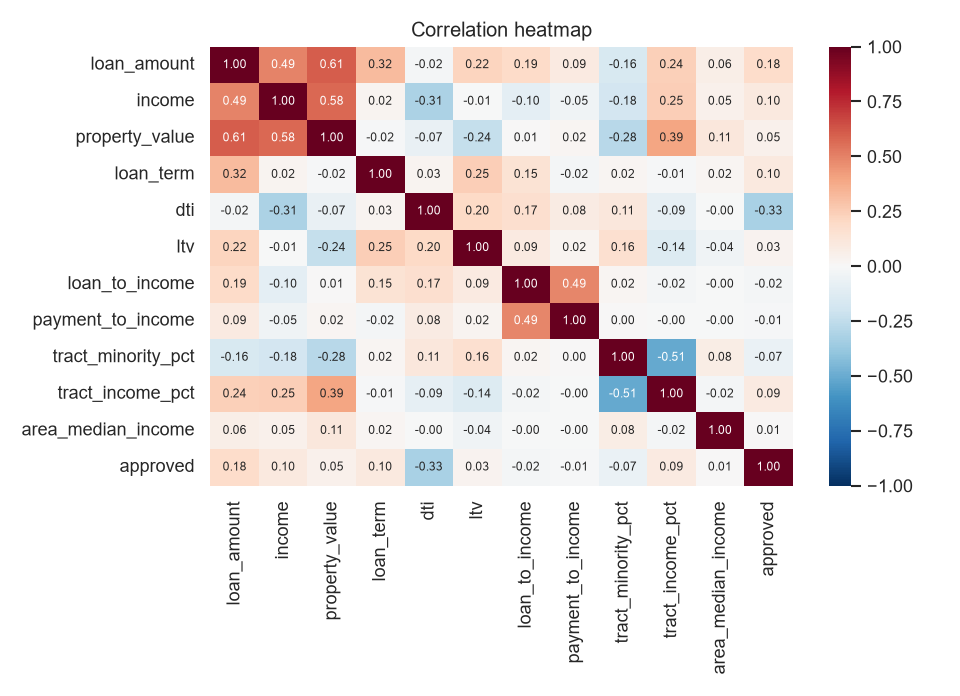

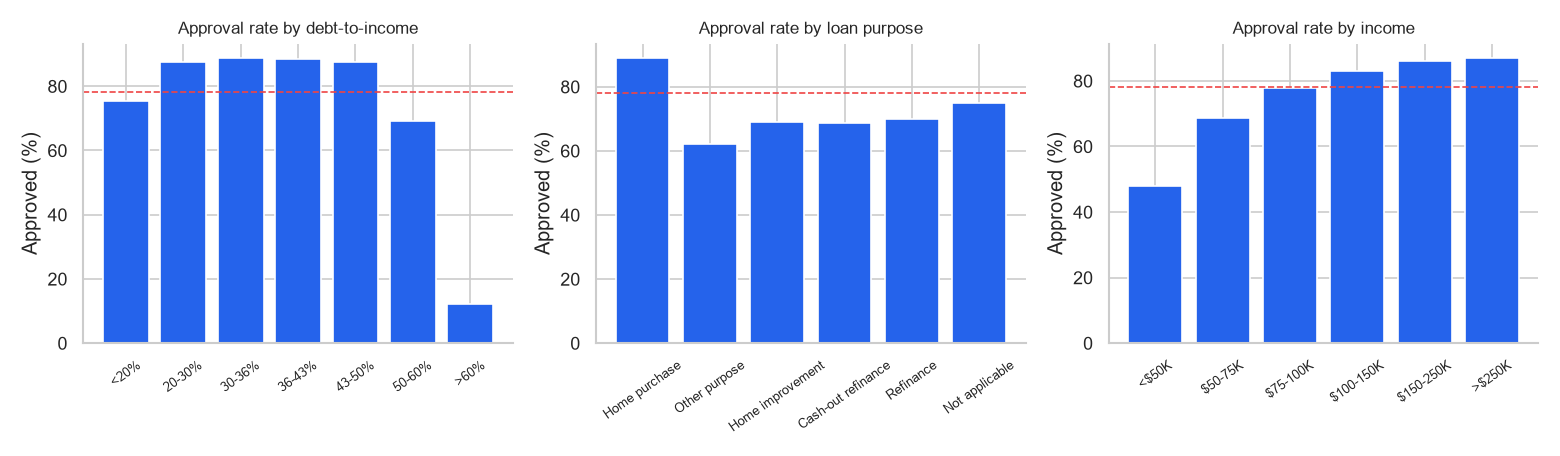

In [4]:
log("STEP 2 - Exploratory analysis")


def rate_by(col: str, order=None) -> list[dict]:
    g = df.groupby(col, observed=True)[TARGET].agg(applications="count", approval_rate="mean").reset_index()
    g = g.rename(columns={col: "group"})
    if order:
        g = g.set_index("group").reindex([o for o in order if o in set(g["group"])]).reset_index()
    else:
        g = g.sort_values("applications", ascending=False)
    g["approval_rate"] = g["approval_rate"].round(4)
    return g.to_dict(orient="records")


def binned(col: str, bins, labels) -> list[dict]:
    b = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    g = df.groupby(b, observed=True)[TARGET].agg(applications="count", approval_rate="mean").reset_index()
    g.columns = ["group", "applications", "approval_rate"]
    g["group"] = g["group"].astype(str)
    return g.round(4).to_dict(orient="records")


eda = {
    "approval_rate": round(float(df[TARGET].mean()), 4),
    "applications": int(len(df)), "approved": int(df[TARGET].sum()), "denied": int((1 - df[TARGET]).sum()),
    "by_loan_purpose": rate_by("loan_purpose"), "by_loan_type": rate_by("loan_type"), "by_lien": rate_by("lien"),
    "by_occupancy": rate_by("occupancy"), "by_co_applicant": rate_by("co_applicant"), "by_credit_line": rate_by("credit_line"),
    "by_sex": rate_by("sex"), "by_age": rate_by("age_band", AGE_ORDER), "by_race": rate_by("race"),
    "by_ethnicity": rate_by("ethnicity"),
    "by_dti": binned("dti", [0, 20, 30, 36, 43, 50, 60, 100], ["<20%", "20-30%", "30-36%", "36-43%", "43-50%", "50-60%", ">60%"]),
    "by_income": binned("income", [0, 50e3, 75e3, 100e3, 150e3, 250e3, 1e12], ["<$50K", "$50-75K", "$75-100K", "$100-150K", "$150-250K", ">$250K"]),
    "by_loan_amount": binned("loan_amount", [0, 50e3, 100e3, 250e3, 500e3, 750e3, 1e12], ["<$50K", "$50-100K", "$100-250K", "$250-500K", "$500-750K", ">$750K"]),
    "by_ltv": binned("ltv", [0, 60, 80, 90, 95, 100, 150], ["<60%", "60-80%", "80-90%", "90-95%", "95-100%", ">100%"]),
    "denial_reasons": df.loc[df[TARGET] == 0, "denial_reason"].value_counts(normalize=True).round(4).to_dict(),
    "income_hist": {"approved": np.histogram(df.loc[df[TARGET] == 1, "income"].dropna().clip(upper=400e3), bins=40, range=(0, 400e3))[0].tolist(),
                    "denied": np.histogram(df.loc[df[TARGET] == 0, "income"].dropna().clip(upper=400e3), bins=40, range=(0, 400e3))[0].tolist(),
                    "edges": np.linspace(0, 400e3, 41).round(0).tolist()},
    "loan_hist": {"approved": np.histogram(df.loc[df[TARGET] == 1, "loan_amount"].clip(upper=1e6), bins=40, range=(0, 1e6))[0].tolist(),
                  "denied": np.histogram(df.loc[df[TARGET] == 0, "loan_amount"].clip(upper=1e6), bins=40, range=(0, 1e6))[0].tolist(),
                  "edges": np.linspace(0, 1e6, 41).round(0).tolist()},
    "correlation": df[NUMERIC + [TARGET]].corr().round(3).to_dict(),
    "medians": {"approved": df[df[TARGET] == 1][NUMERIC].median().round(2).to_dict(),
                "denied": df[df[TARGET] == 0][NUMERIC].median().round(2).to_dict()},
}

fig, ax = plt.subplots(figsize=(8, 5.8))
sns.heatmap(df[NUMERIC + [TARGET]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})
ax.set_title("Correlation heatmap")
fig.tight_layout(); fig.savefig(ART / "figures" / "correlation.png"); plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, key, title in zip(axes, ("by_dti", "by_loan_purpose", "by_income"),
                          ("Approval rate by debt-to-income", "Approval rate by loan purpose", "Approval rate by income")):
    g = pd.DataFrame(eda[key])
    ax.bar(g["group"], g["approval_rate"] * 100, color="#2563eb")
    ax.axhline(eda["approval_rate"] * 100, color="#ef4444", ls="--", lw=1)
    ax.set_title(title, fontsize=10); ax.set_ylabel("Approved (%)"); ax.tick_params(axis="x", rotation=35, labelsize=8)
fig.tight_layout(); fig.savefig(ART / "figures" / "approval_rates.png"); plt.close(fig)
show_new_figures()

## 3. Split + Preprocessing

In [5]:
log("STEP 3 - Split and preprocessing")
X, y = df[FEATURES], df[TARGET]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
log(f"  train {len(X_tr):,} | validation {len(X_va):,} | test {len(X_te):,}")


def preprocessor() -> ColumnTransformer:
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])


try:
    import torch
    XGB_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    XGB_DEVICE = "cpu"

neg_pos = float((y_tr == 0).sum() / (y_tr == 1).sum())
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=16, min_samples_leaf=10, class_weight="balanced_subsample",
                                            n_jobs=N_JOBS, random_state=SEED),
    "SVM (linear)": CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced", random_state=SEED), cv=3),
    "XGBoost": xgb.XGBClassifier(n_estimators=1500, learning_rate=0.05, max_depth=7, min_child_weight=5, subsample=0.8,
                                 colsample_bytree=0.8, reg_lambda=2.0, scale_pos_weight=neg_pos, tree_method="hist", n_jobs=N_JOBS,
                                 device=XGB_DEVICE, eval_metric="auc", early_stopping_rounds=60, random_state=SEED, verbosity=0),
}

STEP 3 - Split and preprocessing


  train 121,900 | validation 26,121 | test 26,122


## 4. Train + Evaluate

In [6]:
log(f"STEP 4 - Model training (XGBoost on {XGB_DEVICE})")
pre = preprocessor().fit(X_tr)
Z_tr, Z_va, Z_te = pre.transform(X_tr), pre.transform(X_va), pre.transform(X_te)
feature_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]


def scores(y_true, proba, thr: float) -> dict:
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Accuracy": round(accuracy_score(y_true, pred), 4),
        "Precision": round(precision_score(y_true, pred), 4),          # of predicted approvals, how many were approved
        "Recall": round(recall_score(y_true, pred), 4),                # of real approvals, how many we found
        "F1": round(f1_score(y_true, pred), 4),
        "Denied_recall": round(tn / (tn + fp), 4),                     # of real denials, how many we caught
        "Denied_precision": round(tn / max(tn + fn, 1), 4),
        "Balanced_accuracy": round(balanced_accuracy_score(y_true, pred), 4),
        "ROC_AUC": round(roc_auc_score(y_true, proba), 4),
        "PR_AUC_denied": round(average_precision_score(1 - y_true, 1 - proba), 4),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
        "threshold": round(float(thr), 3),
    }


fitted, results, probas, val_probas, timing = {}, {}, {}, {}, {}
for name, model in candidates.items():
    t0 = time.time()
    if name == "XGBoost":
        try:
            model.fit(Z_tr, y_tr, eval_set=[(Z_va, y_va)], verbose=False)
        except Exception as exc:
            log(f"  XGBoost GPU unavailable ({str(exc)[:60]}), using CPU")
            XGB_DEVICE = "cpu"
            model.set_params(device="cpu")
            model.fit(Z_tr, y_tr, eval_set=[(Z_va, y_va)], verbose=False)
        model.set_params(device="cpu")
    else:
        model.fit(Z_tr, y_tr)
    timing[name] = round(time.time() - t0, 1)
    p_va, p_te = model.predict_proba(Z_va)[:, 1], model.predict_proba(Z_te)[:, 1]
    # threshold that maximises balanced accuracy on validation: treats both kinds of mistake as equally serious
    grid = np.linspace(0.05, 0.95, 91)
    thr = float(grid[np.argmax([balanced_accuracy_score(y_va, p_va >= t) for t in grid])])
    fitted[name], probas[name], val_probas[name] = model, p_te, p_va
    results[name] = {"test": scores(y_te, p_te, thr), "test_at_0.5": scores(y_te, p_te, 0.5),
                     "validation_auc": round(roc_auc_score(y_va, p_va), 4), "train_seconds": timing[name]}
    r = results[name]["test"]
    log(f"  {name:20s} AUC {r['ROC_AUC']:.4f}  acc {r['Accuracy']:.4f}  prec {r['Precision']:.4f}  rec {r['Recall']:.4f}  "
        f"F1 {r['F1']:.4f}  denied-recall {r['Denied_recall']:.4f}  thr {thr:.2f}  ({timing[name]}s)")

baseline_acc = round(float(max(y_te.mean(), 1 - y_te.mean())), 4)
best = max(results, key=lambda k: results[k]["validation_auc"])       # chosen on validation
log(f"  --> best model by validation AUC: {best}   (always-approve baseline accuracy {baseline_acc})")

# Class weighting makes the model better at spotting denials but skews its probabilities.
# Isotonic calibration (fitted on validation) maps the score back to a true probability.
calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(val_probas[best], y_va)
cal_va, cal_te = calibrator.predict(val_probas[best]), calibrator.predict(probas[best])
grid = np.linspace(0.05, 0.95, 181)
thr = float(grid[np.argmax([balanced_accuracy_score(y_va, cal_va >= t) for t in grid])])
probas[best] = cal_te
results[best]["test"] = scores(y_te, cal_te, thr)
results[best]["test_at_0.5"] = scores(y_te, cal_te, 0.5)
r = results[best]["test"]
log(f"  {best} after calibration: AUC {r['ROC_AUC']:.4f}  acc {r['Accuracy']:.4f}  prec {r['Precision']:.4f}  rec {r['Recall']:.4f}  "
    f"F1 {r['F1']:.4f}  denied-recall {r['Denied_recall']:.4f}  thr {thr:.3f}")
r5 = results[best]["test_at_0.5"]
log(f"  {best} at the plain 0.5 cut-off: acc {r5['Accuracy']:.4f}  rec {r5['Recall']:.4f}  denied-recall {r5['Denied_recall']:.4f}")

STEP 4 - Model training (XGBoost on cuda)


  Logistic Regression  AUC 0.8302  acc 0.7485  prec 0.9090  rec 0.7532  F1 0.8238  denied-recall 0.7319  thr 0.49  (0.6s)


  Decision Tree        AUC 0.8714  acc 0.8032  prec 0.9234  rec 0.8155  F1 0.8661  denied-recall 0.7594  thr 0.46  (0.9s)


  Random Forest        AUC 0.8961  acc 0.8180  prec 0.9361  rec 0.8231  F1 0.8760  denied-recall 0.8001  thr 0.55  (11.6s)


  SVM (linear)         AUC 0.8299  acc 0.7301  prec 0.9130  rec 0.7231  F1 0.8070  denied-recall 0.7549  thr 0.79  (3.7s)


  XGBoost              AUC 0.9019  acc 0.8464  prec 0.9325  rec 0.8659  F1 0.8980  denied-recall 0.7769  thr 0.51  (3.5s)


  --> best model by validation AUC: XGBoost   (always-approve baseline accuracy 0.7806)


  XGBoost after calibration: AUC 0.9014  acc 0.8480  prec 0.9317  rec 0.8690  F1 0.8993  denied-recall 0.7736  thr 0.775


  XGBoost at the plain 0.5 cut-off: acc 0.8902  rec 0.9736  denied-recall 0.5935


## 5. Explainability

In [7]:
log("STEP 5 - Feature importance and explainability")
bm = fitted[best]
sample = np.random.RandomState(SEED).choice(len(Z_te), 8000, replace=False)
perm = permutation_importance(bm, Z_te[sample], y_te.iloc[sample], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=feature_names)
# fold one-hot columns and missing flags back into the original feature they came from
origin = {}
for f in feature_names:
    base = f.replace("missingindicator_", "")
    origin[f] = next((c for c in CATEGORICAL if base.startswith(c + "_")), base)
importance = imp.groupby(origin).sum().sort_values(ascending=False).clip(lower=0)
importance = (importance / importance.sum()).round(4)
log("  top drivers: " + ", ".join(f"{k} {v:.0%}" for k, v in importance.head(6).items()))

xgb_model = fitted["XGBoost"]
contrib = xgb_model.get_booster().predict(xgb.DMatrix(Z_te[sample[:4000]], feature_names=feature_names), pred_contribs=True)
shap_abs = pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=feature_names).groupby(origin).sum().sort_values(ascending=False)

STEP 5 - Feature importance and explainability


  top drivers: dti 42%, loan_purpose 21%, ltv 11%, loan_term 5%, property_value 5%, loan_type 4%


## 6. Fairness Audit

In [8]:
log("STEP 6 - Fairness audit (protected attributes were not model inputs)")
te = df.loc[X_te.index, PROTECTED].copy()
te["actual"], te["proba"] = y_te.values, probas[best]
te["pred"] = (te["proba"] >= results[best]["test"]["threshold"]).astype(int)
fairness = {}
for col in PROTECTED:
    rows = []
    for g, part in te.dropna(subset=[col]).groupby(col):
        if len(part) < 200:
            continue
        ok = part[part["actual"] == 1]
        rows.append({"group": g, "applications": int(len(part)), "actual_approval_rate": round(float(part["actual"].mean()), 4),
                     "model_approval_rate": round(float(part["pred"].mean()), 4),
                     "wrongly_denied_rate": round(float((ok["pred"] == 0).mean()), 4)})
    if col == "age_band":
        rows.sort(key=lambda r: AGE_ORDER.index(r["group"]))
    else:
        rows.sort(key=lambda r: -r["applications"])
    fairness[col] = rows
    rates = [r["model_approval_rate"] for r in rows]
    log(f"  {col:10s} model approval rate ranges {min(rates):.1%} .. {max(rates):.1%} "
        f"(actual {min(r['actual_approval_rate'] for r in rows):.1%} .. {max(r['actual_approval_rate'] for r in rows):.1%})")

STEP 6 - Fairness audit (protected attributes were not model inputs)


  sex        model approval rate ranges 65.6% .. 81.4% (actual 73.4% .. 84.5%)


  age_band   model approval rate ranges 60.5% .. 80.8% (actual 71.5% .. 83.7%)


  race       model approval rate ranges 58.5% .. 83.4% (actual 64.0% .. 85.1%)


  ethnicity  model approval rate ranges 60.9% .. 77.3% (actual 66.4% .. 80.7%)


## 7. Save

STEP 7 - Saving model, metrics and figures


TASK 4 COMPLETE


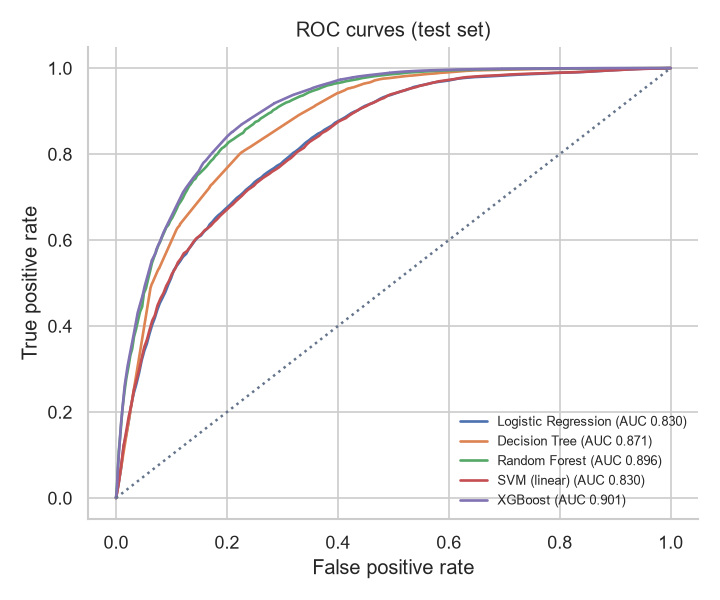

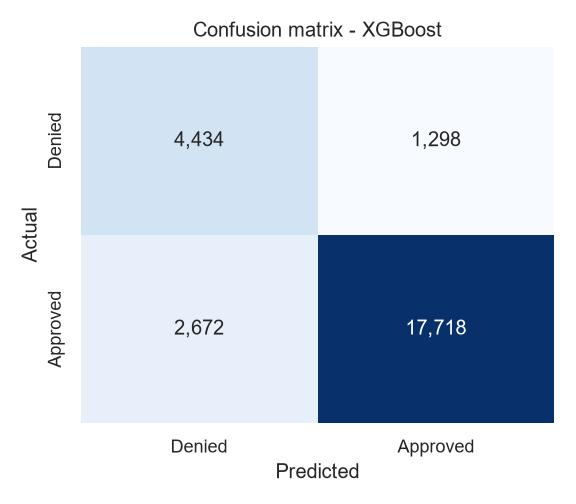

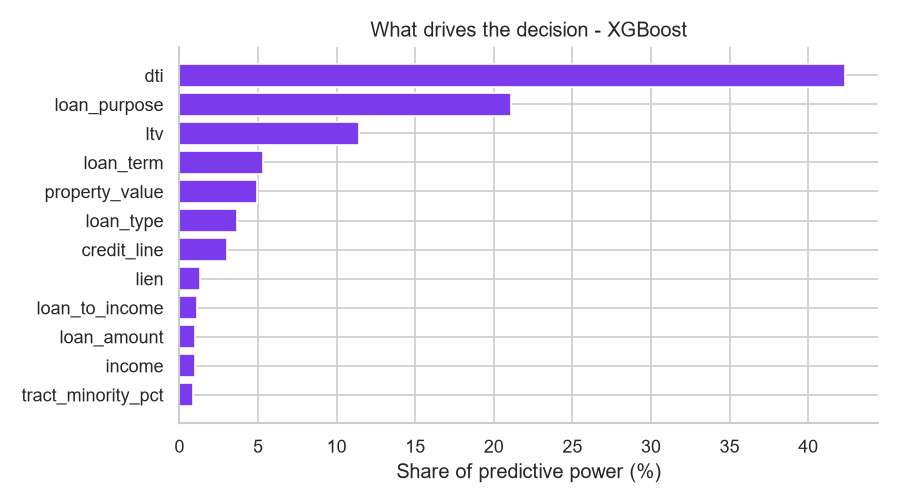

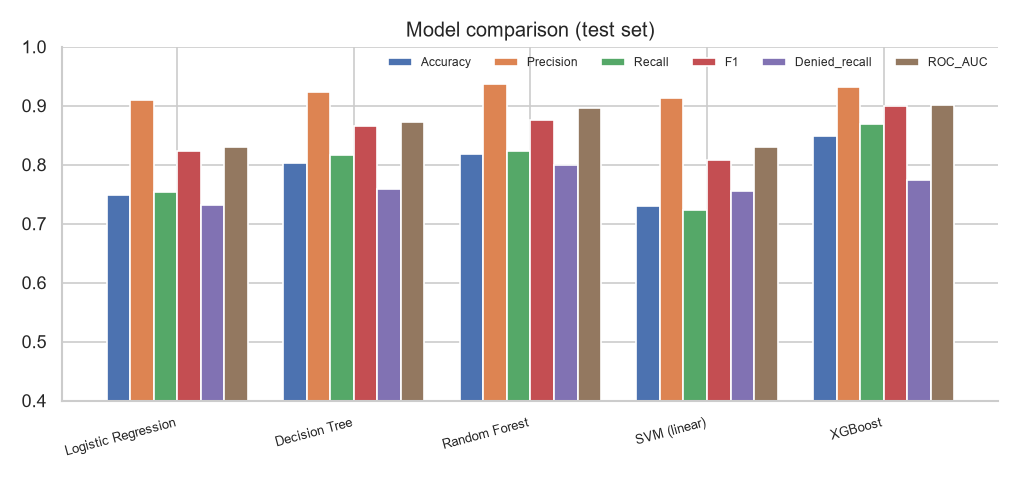

In [9]:
log("STEP 7 - Saving model, metrics and figures")
joblib.dump({"preprocessor": pre, "model": bm, "calibrator": calibrator, "xgb": xgb_model, "features": FEATURES, "numeric": NUMERIC,
             "categorical": CATEGORICAL, "feature_names": feature_names, "origin": origin, "best": best,
             "threshold": results[best]["test"]["threshold"],
             "medians": X_tr[NUMERIC].median().to_dict(),
             "options": {c: sorted(X_tr[c].dropna().unique().tolist()) for c in CATEGORICAL}},
            ART / "loan_model.joblib", compress=3)

roc = {}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    k = np.linspace(0, len(fpr) - 1, 120).astype(int)
    roc[name] = {"fpr": fpr[k].round(4).tolist(), "tpr": tpr[k].round(4).tolist()}

# calibration and score distribution of the chosen model, for the dashboard
pb = probas[best]
bins = np.linspace(0, 1, 11)
which = np.clip(np.digitize(pb, bins) - 1, 0, 9)
calibration = [{"predicted": round(float(pb[which == i].mean()), 4), "actual": round(float(y_te.values[which == i].mean()), 4),
                "count": int((which == i).sum())} for i in range(10) if (which == i).sum() > 0]
thr_curve = [{"threshold": round(float(t), 2), **{k: scores(y_te, pb, t)[k] for k in ("Accuracy", "Precision", "Recall", "Denied_recall", "F1")}}
             for t in np.linspace(0.1, 0.9, 33)]

metrics = {
    "task": "Loan Approval Prediction System",
    "dataset": "HMDA 2023, Colorado (US Consumer Financial Protection Bureau)",
    "cleaning": cleaning, "eda": eda,
    "split": {"train": len(X_tr), "validation": len(X_va), "test": len(X_te)},
    "features": {"numeric": NUMERIC, "categorical": CATEGORICAL, "excluded_protected": PROTECTED},
    "baseline_accuracy_always_approve": baseline_acc,
    "models": results, "best_model": best, "xgboost_device": XGB_DEVICE,
    "xgboost_trees": int(getattr(xgb_model, "best_iteration", 0) or 0) + 1,
    "importance_permutation": importance.to_dict(),
    "importance_shap": (shap_abs / shap_abs.sum()).round(4).to_dict(),
    "fairness": fairness, "roc": roc, "calibration": calibration, "threshold_curve": thr_curve,
    "score_hist": {"approved": np.histogram(pb[y_te.values == 1], bins=25, range=(0, 1))[0].tolist(),
                   "denied": np.histogram(pb[y_te.values == 0], bins=25, range=(0, 1))[0].tolist()},
}
(ART / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
# a sample of real test applications with the model's score, for the dashboard table
out = X_te.copy()
out["actual"] = np.where(y_te == 1, "Approved", "Denied")
out["approval_probability"] = pb.round(4)
out["prediction"] = np.where(pb >= results[best]["test"]["threshold"], "Approved", "Denied")
out.sample(3000, random_state=SEED).round(3).to_csv(ART / "test_predictions_sample.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 5))
for name in results:
    ax.plot(roc[name]["fpr"], roc[name]["tpr"], lw=1.6, label=f"{name} (AUC {results[name]['test']['ROC_AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls=":", color="#64748b")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves (test set)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(ART / "figures" / "roc_curves.png"); plt.close(fig)

cm = results[best]["test"]["confusion"]
fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]], annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Denied", "Approved"], yticklabels=["Denied", "Approved"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix - {best}")
fig.tight_layout(); fig.savefig(ART / "figures" / "confusion_matrix.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
top = importance.head(12).iloc[::-1]
ax.barh(top.index, top.values * 100, color="#7c3aed")
ax.set_xlabel("Share of predictive power (%)"); ax.set_title(f"What drives the decision - {best}")
fig.tight_layout(); fig.savefig(ART / "figures" / "feature_importance.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 4))
m = pd.DataFrame({k: v["test"] for k, v in results.items()}).T[["Accuracy", "Precision", "Recall", "F1", "Denied_recall", "ROC_AUC"]].astype(float)
m.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylim(0.4, 1.0); ax.set_title("Model comparison (test set)"); ax.legend(ncol=6, fontsize=7, frameon=False)
ax.set_xticklabels(m.index, rotation=15, ha="right", fontsize=8)
fig.tight_layout(); fig.savefig(ART / "figures" / "model_comparison.png"); plt.close(fig)
log("TASK 4 COMPLETE")
show_new_figures()